# Load libraries

In [2]:
import matplotlib
import numpy as np
import matplotlib.pyplot as plt
import os
from os import listdir
from os.path import isfile, join
import tifffile as tiff # you might have to install this with 'pip install tifffile'

# Print files in the current working directory (cwd)

In [3]:
folder = os.getcwd()
files = listdir(folder)

for i, f_i in enumerate(files):
    print(i, f_i)

0 12.tif
1 389.tif
2 392.tif
3 430.tif
4 502.tif
5 570.tif
6 81.tif
7 92.tif
8 edges.txt
9 Load_and_plot_Tiff.ipynb
10 spectrum.txt


# Read and plot image file

In [41]:
# Convert images to arrays
order = np.array([5, 4, 3, 2, 1, 7, 6, 0])
kk = np.array([570, 502, 430, 392, 389, 92, 81, 12])


img= tiff.imread(files[order[1]])
img_array = np.array(img).astype('float64')
print(np.shape(img_array))

(1080, 1440, 3)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0..1022].


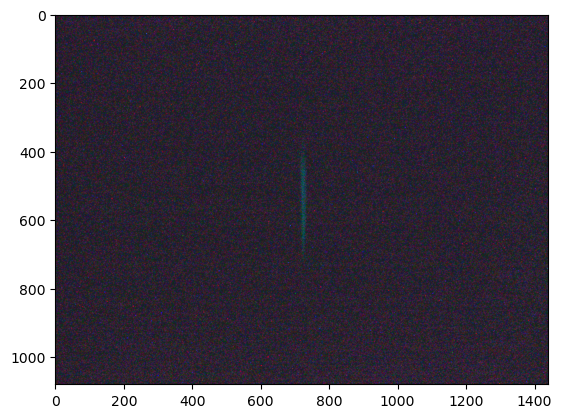

In [42]:
# Plot example image
plt.imshow(img, vmin=1000,vmax=0) 

# Plot linecut

In [13]:
y_max, x_max, c_max = np.shape(img_array)

x = np.linspace(0, x_max - 1, x_max)

y = 550
rangee = 50

# chose color channel
c = 1

cts = (img_array[y, :, 0] + img_array[y, :, 1] + img_array[y, :, 2]) / 3

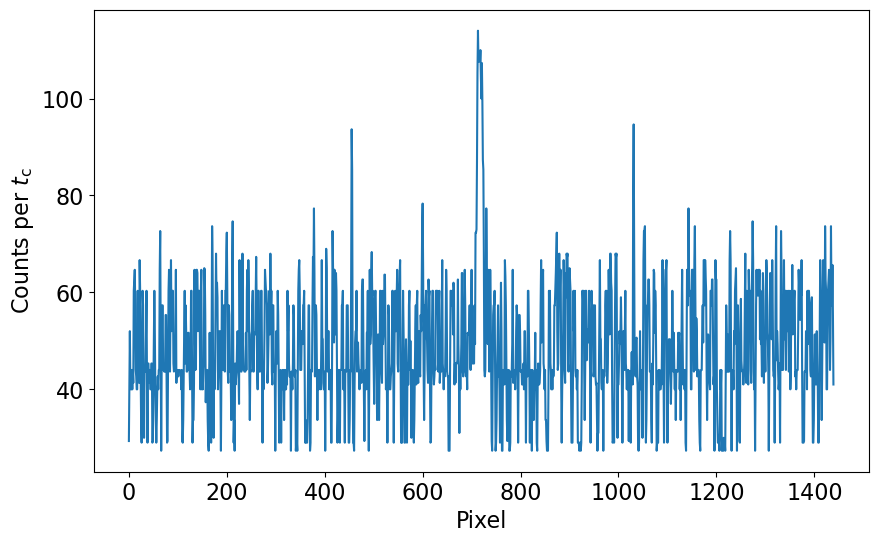

In [7]:
# Plot Data
plt.figure(
    num=1,
    figsize=(10,6),
    facecolor='white')
plt.xlabel(r'Pixel', fontsize=16)
plt.ylabel(r'Counts per $t_\mathrm{c}$', fontsize=16)
plt.plot(x, cts)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.show()

In [7]:
popt = np.loadtxt("../../popt.txt")
k0 = popt[0]
b = popt[1]
d = popt[3]
p_cent = 720
print(k0)
print(b)
print(d)

def lamda(pp, kk):
    return b * ((kk - k0) - (pp - p_cent) / d)

1126.0
-0.7850772089259566
25.77604083290055


In [10]:
for h in range(len(order)):
    img= tiff.imread(files[order[h]])
    img_array = np.array(img).astype('float64')
    k_val = kk[h]
    y_meann = np.zeros(1440)
    
    for i in range(1440):
        y_meann[i] = np.mean(img_array[y - rangee: y + rangee, i, 0]) + np.mean(img_array[y - rangee: y + rangee, i, 1]) + np.mean(img_array[y - rangee: y + rangee, i, 2])

    
    data = np.loadtxt("spectrum.txt", delimiter=',')
    start = 1440
    if data.size == 0:
        start = 0
    else:
        last = data[-1, 0]
        for i in range(len(x)):
            if lamda(i, kk[h]) > last:
                start = i
                break
    start = 0
    print(h)
    print(start)
    print(lamda(x[start], kk[h]))

    ed = open("edges.txt", "a")
    ed.write(str(lamda(x[start], k_val)))
    ed.write(", ")
    ed.write(str(lamda(x[-1], k_val)))
    ed.write("\n")
    ed.close()

    sp = open("spectrum.txt", "a")

    for i in range(start, len(x)):
        sp.write(str(lamda(x[i], k_val)))
        sp.write(", ")
        sp.write(str(y_meann[i]))
        sp.write("\n")
    sp.close()


C:\Users\aprik\AppData\Local\Temp\ipykernel_6388\2552406599.py:11: UserWarning: loadtxt: input contained no data: "spectrum.txt"
  data = np.loadtxt("spectrum.txt", delimiter=',')


0
0
414.5734319267305
1
0
467.9586821336955
2
0
524.4842411763644
3
0
554.3171751155508
4
0
556.6724067423286
5
0
789.8403377933378
6
0
798.4761870915232
7
0
852.6465145074142
